In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("listings_clean.csv")
print(df.shape)

(8072, 13)


Median price by room type

In [2]:
df.groupby("room_type")["price"].agg(["count", "median"]).sort_values("median", ascending=False)

,count,median
room_type,,
Entire home/apt,5796,154.00
Hotel room,53,130.00
Private room,2147,85.25
Shared room,76,27.50


Median price by guests and room type

In [3]:
subset = df[df["room_type"].isin(["Entire home/apt", "Private room"]) & (df["accommodates"] <= 6)]
pivot = subset.groupby(["accommodates", "room_type"])["price"].median().unstack()
pivot

room_type,Entire home/apt,Private room
accommodates,,
1,78.570,66.00
2,113.200,87.33
3,129.170,94.00
4,167.400,115.00
5,208.330,156.05
6,226.625,179.70


Chart 1, price by guests and room type

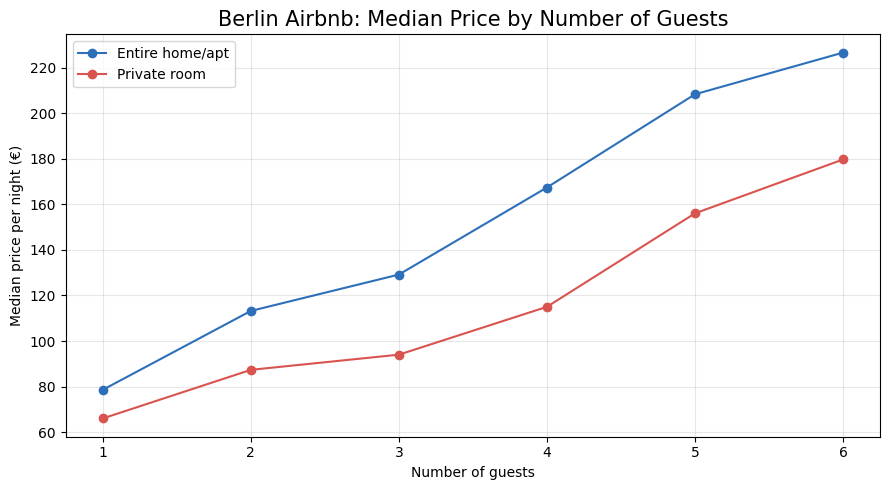

In [4]:
pivot.plot(marker="o", figsize=(9, 5), color=["#2E6FBA", "#D9534F"])
plt.title("Berlin Airbnb: Median Price by Number of Guests", fontsize=15)
plt.xlabel("Number of guests")
plt.ylabel("Median price per night (€)")
plt.legend(title="")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../images/price_by_guests.png", dpi=200)
plt.show()

What is linked to price?

In [5]:
cols = ["price", "accommodates", "bedrooms", "minimum_nights",
        "availability_365", "number_of_reviews", "review_scores_rating"]
corr = df[cols].corr(method="spearman")["price"].drop("price").sort_values()
corr.round(2)

minimum_nights         -0.36
availability_365       -0.03
review_scores_rating    0.02
number_of_reviews       0.20
bedrooms                0.45
accommodates            0.59
Name: price, dtype: float64

Numbers close to 1 mean “higher price goes with higher value”. Numbers close to 0 mean “no clear link”. Negative numbers mean the opposite.

Chart 2, factors linked to price

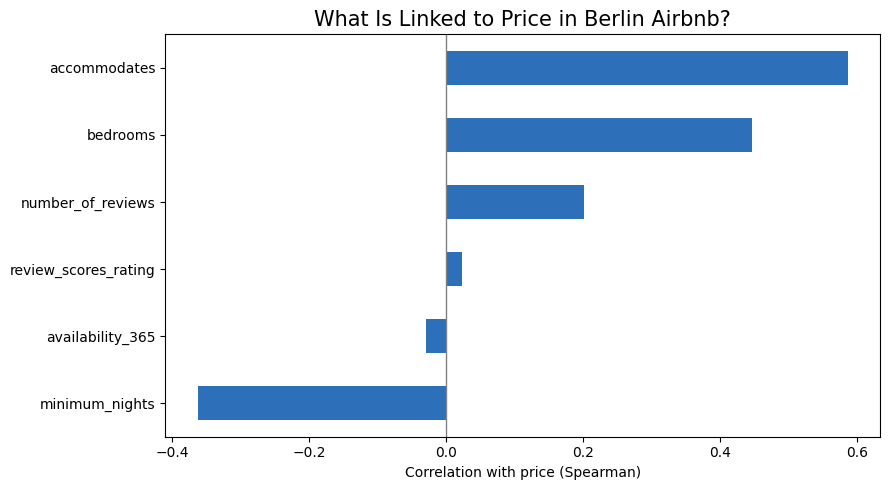

In [6]:
corr.plot(kind="barh", figsize=(9, 5), color="#2E6FBA")
plt.title("What Is Linked to Price in Berlin Airbnb?", fontsize=15)
plt.xlabel("Correlation with price (Spearman)")
plt.axvline(0, color="grey", linewidth=1)
plt.tight_layout()
plt.savefig("../images/price_correlations.png", dpi=200)
plt.show()

Do reviews matter for price?

In [7]:
df["rating_band"] = pd.cut(df["review_scores_rating"], bins=[0, 4.5, 4.8, 5.0],
                           labels=["up to 4.5", "4.5 to 4.8", "above 4.8"])
print(df.groupby("rating_band", observed=True)["price"].agg(["count", "median"]))
print(df.groupby("has_reviews")["price"].median())

             count  median
rating_band               
up to 4.5      995  123.67
4.5 to 4.8    2063  138.64
above 4.8     3761  140.00
has_reviews
False     80.81
True     138.00
Name: price, dtype: float64


##  Notes: What Is Linked to Price

- Room type: median price is [Step 2 entire homes] for entire homes and [Step 2 private rooms] for private rooms.
- Guests: in entire homes, the median price rises from 78.57 for 1 guest to 226.63 for 6 guests. Private rooms rise from 66.00 to 179.70. The gap between the two grows from about 13 per night (1 guest) to about 52 (4 to 5 guests) and is about 47 for 6 guests.
- Correlations (Spearman): size is most linked to price: guests (0.59) and bedrooms (0.45). Longer minimum stays are linked to lower nightly prices (-0.36). Number of reviews (0.20) is only weakly linked, and availability (-0.03) and rating (0.02) show no clear link.
- Reviews: listings with no reviews have a median price of 80.81, compared with 138.00 for listings with reviews. Among rated listings, the median is 123.67 for ratings up to 4.5, 138.64 for 4.5 to 4.8 and 140.00 above 4.8. Only low-rated listings are somewhat cheaper (about 16 less). Between the two higher groups the difference is tiny, so rating alone does not explain price.
- Limits: correlation does not show cause. Guests and bedrooms are linked with each other. Listings with no reviews may be new or inactive, and long minimum stays may be monthly rentals, but I have not tested either.

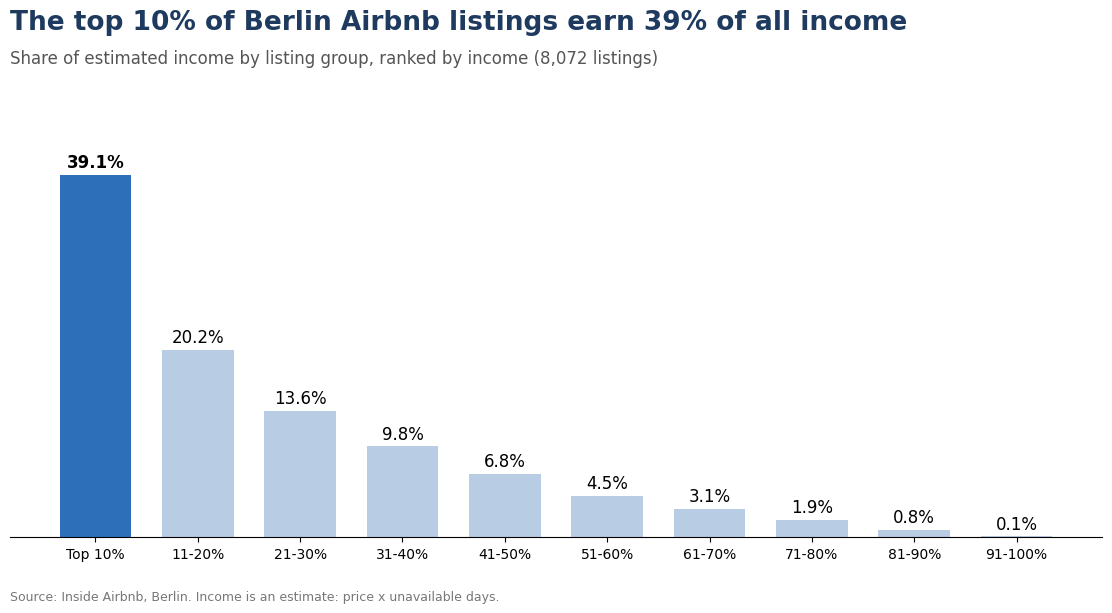

In [8]:
import matplotlib.pyplot as plt

shares = [39.1, 20.2, 13.6, 9.8, 6.8, 4.5, 3.1, 1.9, 0.8, 0.1]
labels = ["Top 10%"] + [f"{a}-{a+9}%" for a in range(11, 100, 10)]
colors = ["#2E6FBA"] + ["#B8CCE4"] * 9

fig, ax = plt.subplots(figsize=(12, 6.27))
bars = ax.bar(labels, shares, color=colors, width=0.7)

for bar, value in zip(bars, shares):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.8, f"{value}%",
            ha="center", fontsize=12, fontweight="bold" if value == 39.1 else "normal")

ax.set_ylim(0, 46)
ax.set_yticks([])
ax.tick_params(axis="x", labelsize=10)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

fig.text(0.06, 0.93, "The top 10% of Berlin Airbnb listings earn 39% of all income",
         fontsize=19, fontweight="bold", color="#1F3A5F")
fig.text(0.06, 0.875, "Share of estimated income by listing group, ranked by income (8,072 listings)",
         fontsize=12, color="#555555")
fig.text(0.06, 0.02, "Source: Inside Airbnb, Berlin. Income is an estimate: price x unavailable days.",
         fontsize=9, color="#777777")

plt.subplots_adjust(top=0.80, bottom=0.12, left=0.06, right=0.97)
plt.savefig("../images/income_share.png", dpi=150)
plt.show()

In [9]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

df = pd.read_csv("listings_clean.csv")
conn = sqlite3.connect("airbnb.db")
print(df.shape)

(8072, 13)


In [10]:
g = df.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"])
g = g[g["count"] >= 30].sort_values("median")
extremes = pd.concat([g.head(8), g.tail(8)])
extremes

,count,median
neighbourhood_cleansed,,
Ost 2,34,77.210
Mierendorffplatz,31,80.090
Zehlendorf Nord,42,86.790
Parkviertel,87,87.000
Volkspark Wilmersdorf,72,88.100
Tempelhof,119,90.000
Rudow,40,93.335
Osloer Straße,71,93.960
Halensee,65,149.270


Chart 3, price by neighborhood

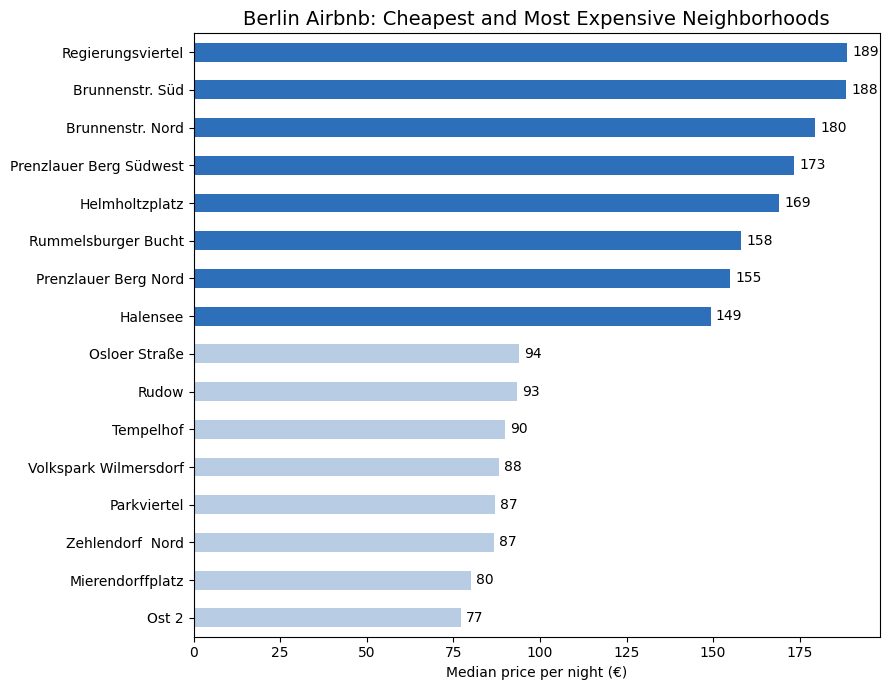

In [11]:
colors = ["#B8CCE4"] * 8 + ["#2E6FBA"] * 8
ax = extremes["median"].plot(kind="barh", figsize=(9, 7), color=colors)
ax.set_title("Berlin Airbnb: Cheapest and Most Expensive Neighborhoods", fontsize=14)
ax.set_xlabel("Median price per night (€)")
ax.set_ylabel("")
for i, v in enumerate(extremes["median"]):
    ax.text(v + 1.5, i, f"{v:.0f}", va="center", fontsize=10)
plt.tight_layout()
plt.savefig("../images/price_by_neighbourhood.png", dpi=200)
plt.show()

Unavailable days by month
We leave out September 2026 and September 2027, because they are partial months.

In [12]:
m = pd.read_sql_query("""
SELECT strftime('%Y-%m', date) AS month,
       ROUND(100.0 * SUM(CASE WHEN available = 'f' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_unavailable
FROM calendar
GROUP BY month
ORDER BY month;
""", conn)
m = m[~m["month"].isin(["2026-09", "2027-09"])]
m

,month,pct_unavailable
1,2026-10,47.2
2,2026-11,33.5
3,2026-12,31.0
4,2027-01,27.6
5,2027-02,27.3
6,2027-03,29.8
7,2027-04,34.7
8,2027-05,34.4
9,2027-06,37.8
10,2027-07,43.6


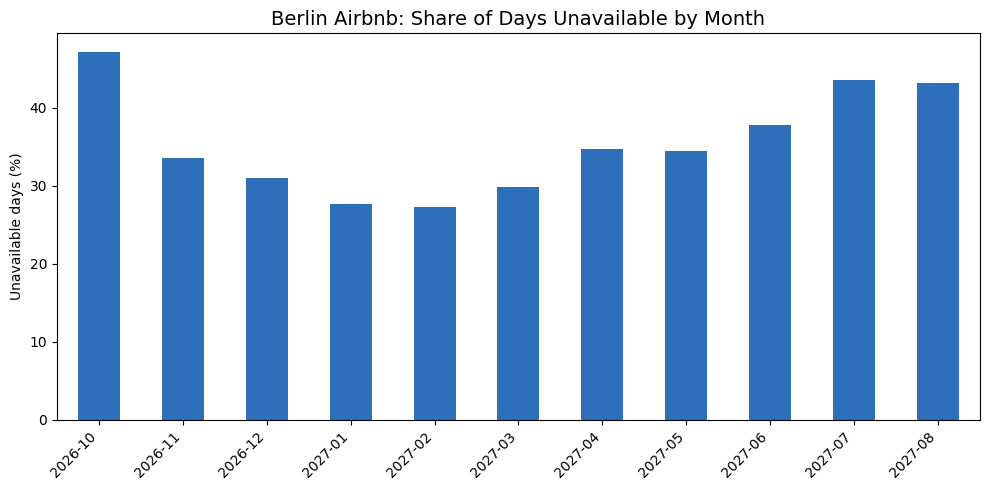

In [13]:
ax = m.plot(x="month", y="pct_unavailable", kind="bar", figsize=(10, 5),
            color="#2E6FBA", legend=False)
ax.set_title("Berlin Airbnb: Share of Days Unavailable by Month", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("Unavailable days (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../images/unavailable_by_month.png", dpi=200)
plt.show()

##  Notes: Charts and Main Findings

- Neighborhoods (30+ listings each): the median price per night ranges from 77 (Ost 2) to 189 (Regierungsviertel), so the most expensive area costs about 2.5x the cheapest. The most expensive areas are mostly central ones around Mitte and Prenzlauer Berg (Brunnenstr. Süd 188, Brunnenstr. Nord 180, Prenzlauer Berg Südwest 173). The cheapest include Ost 2 (77), Mierendorffplatz (80) and Zehlendorf Nord and Parkviertel (87 each).
- Seasonality: unavailable days are lowest in January and February (about 27%) and highest in July and August (about 43%). I left out September 2026 and September 2027, because they are partial months. October 2026 (47.2%) is the nearest month and near dates are more booked, so I do not read it as a peak.
- Limits: unavailable includes days that hosts block, so this shows rough demand, not exact occupancy. Summer may also include hosts blocking days for their own holidays.

### Main findings
1. Income is concentrated: the top 10% of listings earn 39.1% of estimated income, and the bottom half earns 10.4%.
2. Size drives price: guests (0.59) and bedrooms (0.45) are most linked to price. Ratings are not (0.02).
3. Location and season matter: the most expensive neighborhood is about 2.5x the cheapest (189 vs 77 median per night), and unavailable days rise from about 27% in winter to about 43% in summer.

In [17]:
import os
for folder in ["..", "../notebooks"]:
    print(folder, [f for f in os.listdir(folder) if f.endswith(".ipynb")])

.. ['Untitled.ipynb']
../notebooks []
